SAME as neural network_7 but added ReLU activation function (functions defined in nn_functions.py)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import random

In [2]:
from nn_functions import sigma, sigma_der, relu, relu_der, det_activations, grad, neural_network, nn_plot, predict

In [3]:
test_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_test.csv")
train_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_train.csv")

In [4]:
X_train = train_data.drop('label', axis=1).to_numpy()/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()

X_test = test_data.drop('label', axis=1).to_numpy()/255
y_test = test_data['label']

In [5]:
len(X_train), len(y_train), len(X_test), len(y_test)

(60000, 60000, 10000, 10000)

In [6]:
y_train[:10]

array([[0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]])

In [7]:
labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [8]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

Time taken: 346.45 seconds
Accuracy: 0.3128


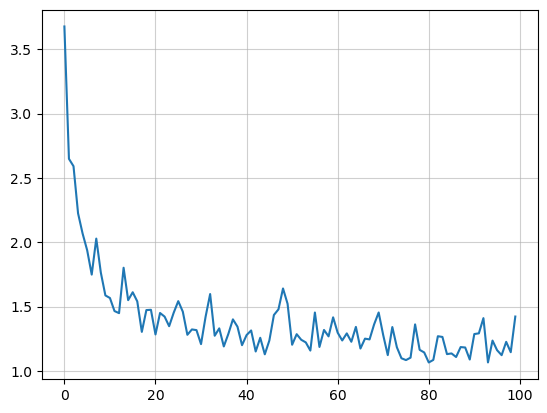

In [9]:
weights, biases, cost = nn_plot(X_train, y_train, X_test, y_test, labels, [16], 1, 1, 60)

In [10]:
x = np.array([-100, -1, 3, 45])
s = [1/(1 + np.exp(-x_item)) for x_item in x]
s

[3.7200759760208356e-44, 0.2689414213699951, 0.9525741268224334, 1.0]

In [11]:
sigma(x)

array([3.72007598e-44, 2.68941421e-01, 9.52574127e-01, 1.00000000e+00])

In [12]:
activations = [relu(act) for act in x]
activations

[0, 0, 3, 45]

In [13]:
np.maximum(0, x)

array([ 0,  0,  3, 45])

In [14]:
np.maximum(0, -3)

0

In [15]:
relu_der(x)

array([0, 0, 1, 1])

In [16]:
y = np.array([[1, -1], [-4, -3.2]])
relu_der(y)

array([[1., 0.],
       [0., 0.]])

In [17]:
np.maximum(0, y)

array([[1., 0.],
       [0., 0.]])

Time taken: 355.65 seconds
Accuracy: 0.1009


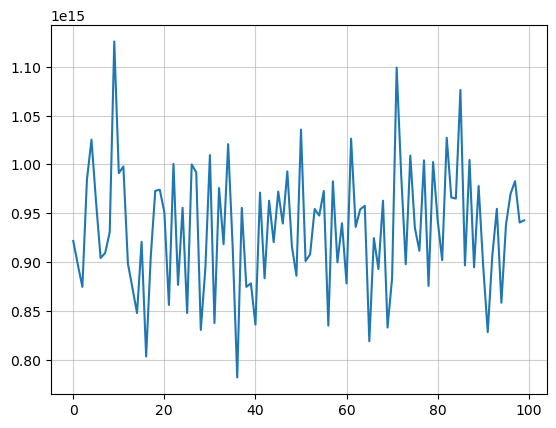

In [18]:
weights, biases, cost = nn_plot(X_train, y_train, X_test, y_test, labels, [16], 1, 1, 60, relu_act=True)

Time taken: 1098.81 seconds
Accuracy: 0.6839


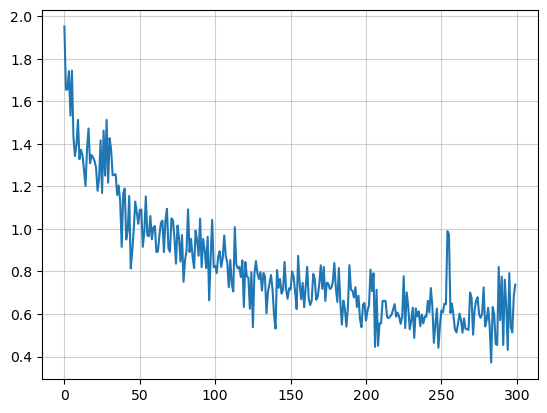

In [19]:
weights, biases, cost = nn_plot(X_train, y_train, X_test, y_test, labels, [16], 2, 3, 60)

/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/nn_functions.py:11: RuntimeWarning: overflow encountered in exp
  s = 1/(1 + np.exp(-x))


Time taken: 1377.43 seconds
Accuracy: 0.4394


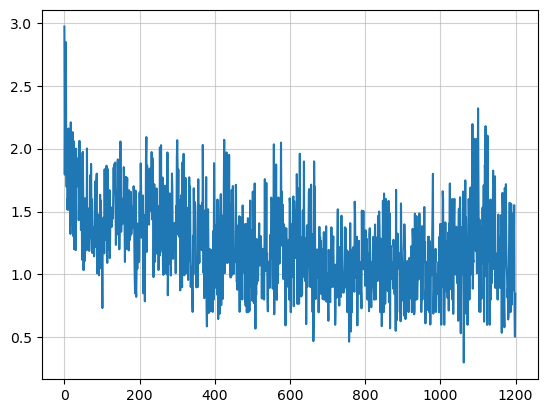

In [22]:
weights, biases, cost = nn_plot(X_train, y_train, X_test, y_test, labels, [30], 3, 2, 10) 

Time taken: 1329.4965407848358 seconds
Accuracy: 0.6086


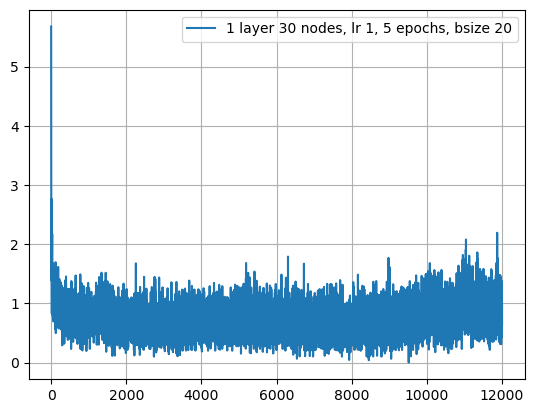

In [55]:
start = time.time()  
activations_5, weights_5, biases_5, cost_5 = neural_network(X_train, y_train, [30], 2, 2, 10) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_5, label="1 layer 30 nodes, lr 1, 5 epochs, bsize 20");
plt.grid();
plt.legend();

y_predict_5 = predict(X_test, weights_5, biases_5, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_5)))

In [56]:
y_test[4231:4241]

4231    8
4232    1
4233    5
4234    3
4235    9
4236    5
4237    9
4238    7
4239    6
4240    9
Name: label, dtype: int64

In [57]:
y_predict_2[4231:4241]

[0, 1, 5, 3, 9, 5, 9, 3, 6, 9]

Time taken: 1081.5163900852203 seconds
Accuracy: 0.5239


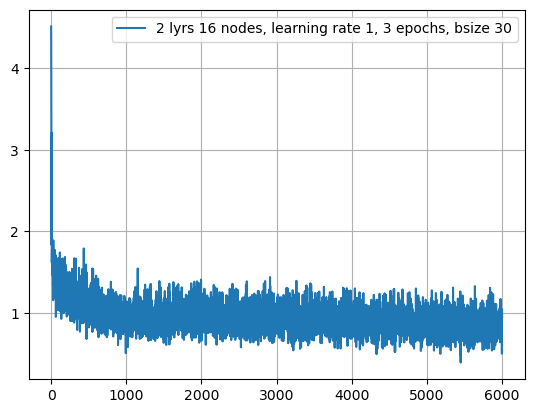

In [58]:
start = time.time()  
activations_6, weights_6, biases_6, cost_6 = neural_network(X_train, y_train, [16, 16], 1, 3, 30) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_6, label="2 lyrs 16 nodes, learning rate 1, 3 epochs, bsize 30");
plt.grid();
plt.legend();

y_predict_6 = predict(X_test, weights_6, biases_6, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_6)))

Time taken: 1752.1690130233765 seconds
Accuracy: 0.7537


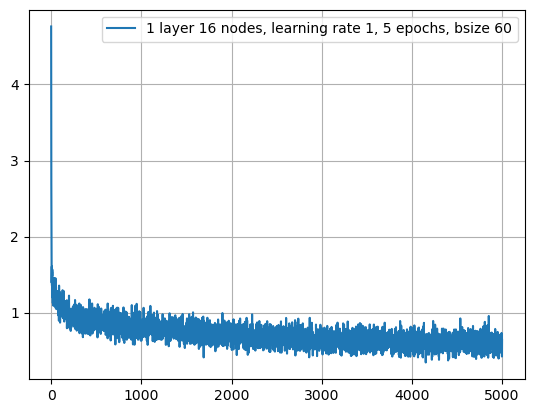

In [59]:
start = time.time()  
activations_6, weights_6, biases_6, cost_6 = neural_network(X_train, y_train, [16], 1, 5, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_6, label="1 layer 16 nodes, learning rate 1, 5 epochs, bsize 60");
plt.grid();
plt.legend();

y_predict_6 = predict(X_test, weights_6, biases_6, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_6)))

In [24]:
X_train = train_data.drop('label', axis=1).to_numpy()[:50001]/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()[:50001]

In [ ]:
start = time.time()  
activations_7, weights_7, biases_7, cost_7 = neural_network(X_train, y_train, [30], 3, 30, 10) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_6, label="1 layer 16 nodes, learning rate 1, 5 epochs, bsize 60");
plt.grid();
plt.legend();

y_predict_6 = predict(X_test, weights_6, biases_6, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_6)))

In [25]:
import platform
print(platform.processor())  # CPU model

i386


In [26]:
import cpuinfo
print(cpuinfo.get_cpu_info()['brand_raw'])

Intel(R) Core(TM) i5-7600 CPU @ 3.50GHz


In [27]:
import psutil
print(psutil.virtual_memory().total / 1e9, "GB RAM")

8.589934592 GB RAM


In [28]:
import os
print(os.name)  # 'posix' (Linux/macOS) or 'nt' (Windows)

posix


In [3]:
import torch
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected")

Torch version: 2.2.2
CUDA available: False
GPU: No GPU detected


In [4]:
print("MPS available:", torch.backends.mps.is_available())

MPS available: True
